<a href="https://colab.research.google.com/github/elizadana29/ST445_Group_1_Oct_23/blob/main/Week%208/2_st445_week8_lab2_eda_challenge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ST445 Week 8 · Lab 2: the EDA challenge

**A team game · about 100 minutes · practises the Week 7 EDA protocol and the Week 8 matrix methods on one dataset**

Two teams, **Team A** and **Team B**, answer questions about the same dataset using exploratory data analysis. After each round, each team **evaluates the other team's answer**: could they understand it clearly, vaguely, or not at all? Points go to the team whose answer was understood. The team with more points at the end wins.

### How a round works (10 minutes)

| Time | What happens |
|---|---|
| 6 minutes | Each team answers **its own question card** (Team A answers card A, Team B card B): code, one chart, and an insight statement |
| 2 minutes | Each team's **presenter** shows the chart and reads the insight statement to the other team (in person, or by sharing the screen) |
| 2 minutes | Each team **scores the other team's answer** with the rubric below, and records the score and a one-line reason |

The two cards in each round practise the **same skill** on different variables, so the round is fair and reduces the likelyhood of teams copying each other. There are **8 rounds** (40 minutes per four rounds, with a 10-minute break between rounds 4 and 5), then a **final question** for both teams, scored by the tutor as a tie-break.

### Scoring rubric: use it for every evaluation

| Points | The other team's answer was ... | In practice |
|---|---|---|
| **1** | understood **clearly** | it answers the question; it states an **observation**, gives specific **evidence** (the chart, with at least one number), and states a **caveat**; the chart is readable (title, labelled axes with units, suitable colours) |
| **0.5** | understood **vaguely** | it answers the question, but the evidence has no number, or the caveat is missing, or the chart is hard to read |
| **0** | **not understood** | it does not answer the question, or it is wrong, or there is no chart or no statement |

**Fair play.** Score the **clarity of the explanation**, not whether you agree with it. Every score needs a one-line reason; a team that disagrees with a score may appeal to the tutor, whose decision is final.

### Roles: rotate them every round

* **Analyst:** writes the code.
* **Writer:** writes the insight statement (observation, evidence, caveat).
* **Presenter:** presents the answer, and leads the scoring of the other team's answer.

With the above three roles per team, swap responsabilities so that everyone takes every role at least once.

**Before you start:** choose **File → Save a copy in Drive**, and fill in your team details in section 1.

---
## 1. Your team

In [2]:
import numpy as np

# 🟢 Fill in, then run
MY_TEAM = "A"                                       # "A" or "B"
TEAM_NAME = "____"                                  # a name for the leaderboard
MEMBERS = ["____", "____", "____", "____", "____"]  # 3, 4 or 5 members

OTHER_TEAM = "B" if MY_TEAM == "A" else "A"
ROLES = ["analyst", "writer", "presenter"]

for r in range(1, 9):
    # Distribute members into roles. If there are 4 or 5 members, some roles will have multiple people
    n_members = len(MEMBERS)
    rotation = {role: [] for role in ROLES}

    # Assign each member to a role based on the round offset
    for i, member in enumerate(MEMBERS):
        role_index = (i - (r - 1)) % len(ROLES)
        rotation[ROLES[role_index]].append(member)

    # Clean up display: if a role has only 1 person, unpack it from list
    rotation_display = {role: names[0] if len(names) == 1 else names for role, names in rotation.items()}
    print(f"round {r}: {rotation_display}")

round 1: {'analyst': ['____', '____'], 'writer': ['____', '____'], 'presenter': '____'}
round 2: {'analyst': ['____', '____'], 'writer': '____', 'presenter': ['____', '____']}
round 3: {'analyst': '____', 'writer': ['____', '____'], 'presenter': ['____', '____']}
round 4: {'analyst': ['____', '____'], 'writer': ['____', '____'], 'presenter': '____'}
round 5: {'analyst': ['____', '____'], 'writer': '____', 'presenter': ['____', '____']}
round 6: {'analyst': '____', 'writer': ['____', '____'], 'presenter': ['____', '____']}
round 7: {'analyst': ['____', '____'], 'writer': ['____', '____'], 'presenter': '____'}
round 8: {'analyst': ['____', '____'], 'writer': '____', 'presenter': ['____', '____']}


### Imports, style and the scoring tool

The cell below also defines `award(round_number, points, reason)`, which records the score **your team gives the other team** after each round, and `scoreboard()`, which shows the totals.

In [3]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, optimal_leaf_ordering, leaves_list, fcluster
from scipy.spatial.distance import squareform, pdist
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.neighbors import kneighbors_graph

OKABE_ITO = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#F0E442", "#000000"]
ORIGIN_COLOURS = {"usa": OKABE_ITO[0], "europe": OKABE_ITO[1], "japan": OKABE_ITO[2]}
sns.set_theme(style="ticks")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

SCORES_GIVEN = {}                              # round -> {"points": ..., "reason": ...}

def award(round_number, points, reason):
    """Record the score your team gives the OTHER team's answer in a round."""
    assert points in (0, 0.5, 1), "points must be 0, 0.5 or 1 (see the rubric)"
    assert len(reason.strip()) >= 10, "give a one-line reason for the score"
    SCORES_GIVEN[round_number] = {"points": points, "reason": reason.strip()}
    print(f"Round {round_number}: Team {OTHER_TEAM} receives {points} point(s). Reason: {reason.strip()}")

def scoreboard():
    """The scores your team has given, as a table, and their total."""
    table = pd.DataFrame(SCORES_GIVEN).T.rename_axis("round")
    total = table["points"].sum() if len(table) else 0
    print(f"Points given to Team {OTHER_TEAM} so far: {total}")
    return table

---
## 2. The dataset: Auto MPG

Fuel consumption and design of **398 cars** sold in the United States between **1970 and 1982**: fuel economy (miles per US gallon, **mpg**: higher is better), number of cylinders, engine displacement (cubic inches), horsepower, weight (pounds), acceleration (seconds from 0 to 60 mph: **lower is faster**), model year, origin (USA, Europe or Japan) and name.

* **Source:** Quinlan, J. R. (1993), "Combining instance-based and model-based learning", *Proceedings of the Tenth International Conference on Machine Learning*, 236–243; [UCI Machine Learning Repository, dataset 9](https://archive.ics.uci.edu/dataset/9/auto+mpg), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Loaded with [`sns.load_dataset("mpg")`](https://seaborn.pydata.org/generated/seaborn.load_dataset.html).
* **Why this dataset:** it needs almost no preprocessing, has a time dimension (model year), groups (origin, cylinders), a few genuinely missing values, a famous outlier, and seven numeric variables for matrix displays.

### Preprocessing, in one cell

In [4]:
# 🟢 Load and prepare the data: one documented cell
raw = sns.load_dataset("mpg")                 # downloads a copy of the UCI file (internet needed)
cars = raw.copy()                             # keep raw unchanged

# 1. The real model year, instead of two digits (70 -> 1970)
cars["year"] = 1900 + cars["model_year"]
cars = cars.drop(columns="model_year")

# 2. Origin as a category with a fixed order, so every chart uses the same order and colours
cars["origin"] = pd.Categorical(cars["origin"], categories=["usa", "europe", "japan"])

# 3. The make (brand), the first word of the name, with the dataset's misspellings corrected
cars["make"] = (cars["name"].str.split().str[0]
                .replace({"chevy": "chevrolet", "chevroelt": "chevrolet", "vw": "volkswagen",
                          "vokswagen": "volkswagen", "toyouta": "toyota", "maxda": "mazda",
                          "mercedes-benz": "mercedes"}))

# 4. Horsepower is missing for 6 cars. We do NOT impute it here: round 2 asks you to examine
#    the gaps. 'complete' keeps only cars with every value, for the matrix methods (rounds 6 to 8)
NUMERIC = ["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "year"]
complete = cars.dropna(subset=NUMERIC).reset_index(drop=True)

# 5. A standardised copy (mean 0, sd 1) for distances between cars, so that no variable
#    dominates because of its units (weight in thousands of pounds would swamp everything else)
Z = (complete[NUMERIC] - complete[NUMERIC].mean()) / complete[NUMERIC].std()

# 6. Checks that fail loudly, that is, raise an error and stop the code from
# running.
assert cars.shape[0] == 398, "unexpected number of cars"
assert complete[NUMERIC].notna().all().all() and len(complete) == 392, "unexpected missing values"

print("all cars:", cars.shape, "| complete cars:", complete.shape)
cars.head()

all cars: (398, 10) | complete cars: (392, 10)


,mpg,cylinders,displacement,horsepower,weight,acceleration,origin,name,year,make
0,18.0,8,307.0,130.0,3504,12.0,usa,chevrolet chevelle malibu,1970,chevrolet
1,15.0,8,350.0,165.0,3693,11.5,usa,buick skylark 320,1970,buick
2,18.0,8,318.0,150.0,3436,11.0,usa,plymouth satellite,1970,plymouth
3,16.0,8,304.0,150.0,3433,12.0,usa,amc rebel sst,1970,amc
4,17.0,8,302.0,140.0,3449,10.5,usa,ford torino,1970,ford


**What you should see:** 398 cars in `cars` and 392 in `complete` (the 6 without horsepower removed). Use **`cars`** for Week 7 questions and **`complete`** and **`Z`** for the matrix questions.

### Your toolkit: helper functions from the Week 8 lecture

These are ready to use, so that you can spend the rounds on analysis rather than on writing algorithms.

In [5]:
# 🟢 Week 8 helpers
def ar_events(D):
    """Gradient-condition violations (anti-Robinson events) of a dissimilarity matrix in its current order."""
    D = np.asarray(D)
    n = len(D)
    count = 0
    for i in range(n):
        for j in range(i + 2, n):
            k = np.arange(i + 1, j)
            count += int((D[i, k] > D[i, j]).sum()) + int((D[k, j] > D[i, j]).sum())
    return count

def seriate(D, method="average"):
    """An order for a dissimilarity matrix: hierarchical clustering + optimal leaf ordering."""
    condensed = squareform(np.asarray(D), checks=False)
    tree = optimal_leaf_ordering(linkage(condensed, method), condensed)
    return leaves_list(tree)

def fiedler_order(X, n_neighbors=10):
    """Spectral seriation: the Fiedler vector of a nearest-neighbour graph, and the order it gives."""
    A = kneighbors_graph(X, n_neighbors=n_neighbors, mode="connectivity").toarray()
    S = (A + A.T) / 2
    L = np.diag(S.sum(axis=1)) - S
    values, vectors = np.linalg.eigh(L)
    fiedler = vectors[:, 1]
    return fiedler, np.argsort(fiedler)

print("toolkit ready: ar_events(D), seriate(D), fiedler_order(X)")

toolkit ready: ar_events(D), seriate(D), fiedler_order(X)


### How to write each answer

For every card: one code cell that produces **one clear chart** (and any numbers you need), then the Markdown answer cell, completed:

> **Observation:** what you found, in one sentence that answers the question.
> **Evidence:** the chart, and at least one number from your output.
> **Caveat:** one thing that could make the observation wrong, or narrower.

Week 7's checklist applies to the chart: a title that states the finding, labelled axes with units, a suitable colour scale, and bars that start at zero.

---
## Round 1 · Week 7 · step 2: univariate distributions

**Hint for both cards:** `sns.histplot`, with a reference line at the median (`ax.axvline`); `.describe()` and `.skew()` for the numbers.

### Card A (Team A answers)

**Question.** How is **fuel economy (`mpg`)** distributed across the 398 cars? What is a typical value, how widely does it vary, and is the distribution symmetric?

In [6]:
# Team A: your code for round 1

✍️ **Our answer (Team A, round 1)**

**Observation:**

**Evidence:**

**Caveat:**

### Card B (Team B answers)

**Question.** How is **horsepower** distributed across the cars? What is a typical value, how widely does it vary, and is the distribution symmetric?

count    392.000000
mean     104.469388
std       38.491160
min       46.000000
25%       75.000000
50%       93.500000
75%      126.000000
max      230.000000
Name: horsepower, dtype: float64
skewness: 1.09


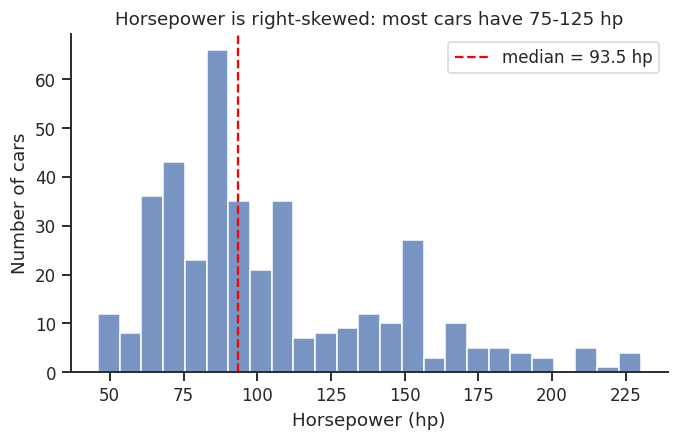

In [37]:
# Team B: your code for round 1
hp = cars["horsepower"]
print(hp.describe())
print("skewness:", round(hp.skew(), 2))

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(hp, bins=25, ax=ax)
ax.axvline(hp.median(), color="red", linestyle="--", label=f"median = {hp.median()} hp")
ax.legend()
ax.set_title("Horsepower is right-skewed: most cars have 75-125 hp")
ax.set_xlabel("Horsepower (hp)")
ax.set_ylabel("Number of cars")
plt.show()

✍️ **Our answer (Team B, round 1)**

**Observation:**

**Evidence:**

**Caveat:**

✍️ **Evaluate the answer**

Now, give a score to the other team's answer using `award()`. Note that is requires three arguments: 1) round number, 2) your score to the OTHER team's answer, and 3) reason for your score.
For example:

`award(1, 1, "clear observation; evidence with numbers; caveat about ...")`

In [8]:
# Score the OTHER team's answer for round 1 (0, 0.5 or 1), with a one-line reason. For example:
# award(1, 1, "clear observation; evidence with numbers; caveat about ...")

---
## Round 2 · Week 7 · steps 3 and 7: missingness and anomalies

**Hint for both cards:** A: `cars.isna().sum()`, then look at the rows with missing horsepower (origin, year). B: a scatter of acceleration against horsepower, and label the points furthest from the trend (`np.polyfit` or by eye).

### Card A (Team A answers)

**Question.** Which values are **missing** in the dataset, for which cars, and could the gaps **bias** an analysis of horsepower?

In [9]:
# Team A: your code for round 2

✍️ **Our answer (Team A, round 2)**

**Observation:**

**Evidence:**

**Caveat:**

### Card B (Team B answers)

**Question.** Which cars are **unusual**: much slower or faster to accelerate than their **horsepower** would suggest? Are they errors or genuine?

                                  name  year  horsepower  weight  \
299                        peugeot 504  1979        71.0    3190   
28                            hi 1200d  1970       193.0    4732   
394                          vw pickup  1982        52.0    2130   
300  oldsmobile cutlass salon brougham  1979        90.0    3420   
160                      buick century  1975       110.0    3907   

     acceleration  predicted  residual  
299          24.8       17.2       7.6  
28           18.5       11.2       7.3  
394          24.6       18.1       6.5  
300          22.2       16.3       5.9  
160          21.0       15.3       5.7  


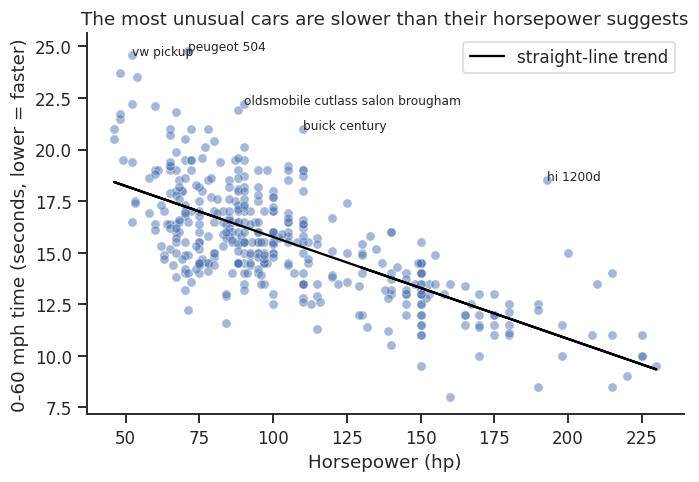

In [38]:
# Team B: your code for round 2
d = cars.dropna(subset=["horsepower"]).copy()

# Fit a straight line: acceleration predicted from horsepower
slope, intercept = np.polyfit(d["horsepower"], d["acceleration"], 1)
d["predicted"] = slope * d["horsepower"] + intercept
d["residual"] = d["acceleration"] - d["predicted"]   # positive = slower than expected

# The 5 cars furthest from the line
unusual = d.loc[d["residual"].abs().sort_values(ascending=False).index[:5]]
print(unusual[["name", "year", "horsepower", "weight", "acceleration", "predicted", "residual"]].round(1))

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.scatterplot(data=d, x="horsepower", y="acceleration", alpha=0.5, ax=ax)
ax.plot(d["horsepower"], d["predicted"], color="black", label="straight-line trend")
for _, row in unusual.iterrows():
    ax.annotate(row["name"], (row["horsepower"], row["acceleration"]), fontsize=8)
ax.legend()
ax.set_title("The most unusual cars are slower than their horsepower suggests")
ax.set_xlabel("Horsepower (hp)")
ax.set_ylabel("0-60 mph time (seconds, lower = faster)")
plt.show()

✍️ **Our answer (Team B, round 2)**

**Observation:**

**Evidence:**

**Caveat:**

✍️ **Evaluate the answer**

Now, give a score to the other team's answer using `award()`.

`award(2, 1, "clear observation; evidence with numbers; caveat about ...")`

In [11]:
# Score the OTHER team's answer for round 2 (0, 0.5 or 1), with a one-line reason
# award(2, 1, "clear observation; evidence with numbers; caveat about ...")

---
## Round 3 · Week 7 · step 4: relationships

**Hint for both cards:** A scatter plot first (`sns.regplot` with `lowess=True` or `order=2` shows the shape), then a correlation (`.corr()`). Remember Anscombe.

### Card A (Team A answers)

**Question.** How are **weight** and **fuel economy** related? Describe the direction, the strength and the shape.

In [12]:
# Team A: your code for round 3

✍️ **Our answer (Team A, round 3)**

**Observation:**

**Evidence:**

**Caveat:**

### Card B (Team B answers)

**Question.** How are **horsepower** and **acceleration** (0–60 mph time) related? Describe the direction, the strength and the shape.

correlation: -0.69
            count  median
horsepower               
(0, 100]      242    16.4
(100, 150]    105    14.0
(150, 250]     45    12.0


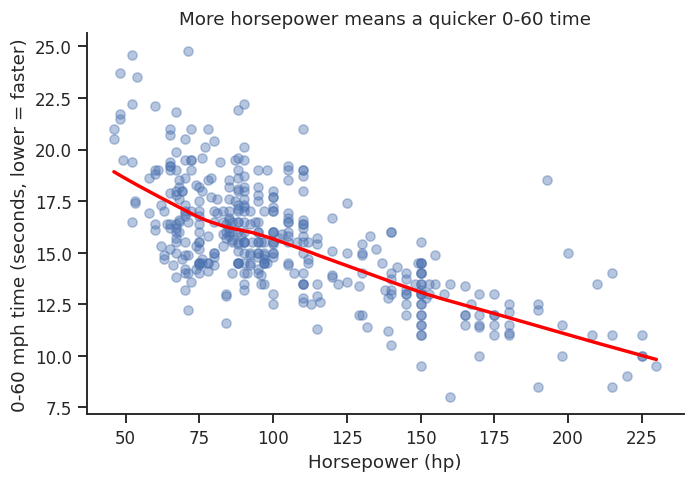

In [39]:
# Team B: your code for round 3
print("correlation:", round(cars["horsepower"].corr(cars["acceleration"]), 2))

# Median 0-60 time in three horsepower groups
hp_group = pd.cut(cars["horsepower"], bins=[0, 100, 150, 250])
print(cars.groupby(hp_group, observed=True)["acceleration"].agg(["count", "median"]))

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.regplot(data=cars, x="horsepower", y="acceleration", lowess=True, ax=ax,
            scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
ax.set_title("More horsepower means a quicker 0-60 time")
ax.set_xlabel("Horsepower (hp)")
ax.set_ylabel("0-60 mph time (seconds, lower = faster)")
plt.show()

✍️ **Our answer (Team B, round 3)**

**Observation:**

**Evidence:**

**Caveat:**

✍️ **Evaluate the answer**

Now, give a score to the other team's answer using `award()`.

`award(3, 1, "clear observation; evidence with numbers; caveat about ...")`

In [14]:
# Score the OTHER team's answer for round 3 (0, 0.5 or 1), with a one-line reason
# award(3, 1, "clear observation; evidence with numbers; caveat about ...")

---
## Round 4 · Week 7 · step 5: groups and subgroups

**Hint for both cards:** A: `pd.cut` to make weight bands, then a box plot or grouped bar of mpg by band and origin (Simpson's paradox from the lecture). B: a box plot of mpg by cylinders, with the group sizes shown.

### Card A (Team A answers)

**Question.** Japanese cars have the best fuel economy overall. Is that **only because they are lighter**? Compare origins **within** weight bands.

In [15]:
# Team A: your code for round 4

✍️ **Our answer (Team A, round 4)**

**Observation:**

**Evidence:**

**Caveat:**

### Card B (Team B answers)

**Question.** How does fuel economy differ by **number of cylinders**? Are any groups **too small** to trust?

           count  median
cylinders               
3              4   20.25
4            204   28.25
5              3   25.40
6             84   19.00
8            103   14.00
                    name  cylinders   mpg
71       mazda rx2 coupe          3  19.0
111            maxda rx3          3  18.0
243           mazda rx-4          3  21.5
274            audi 5000          5  20.3
297   mercedes benz 300d          5  25.4
327  audi 5000s (diesel)          5  36.4
334        mazda rx-7 gs          3  23.7


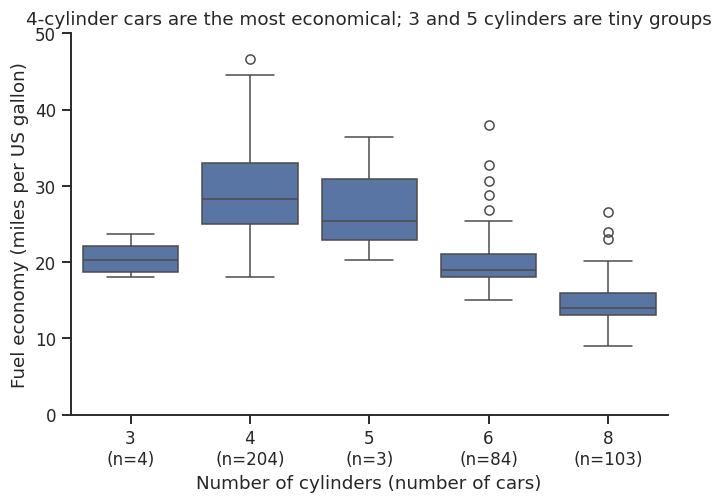

In [40]:
# Team B: your code for round 4
summary = cars.groupby("cylinders")["mpg"].agg(["count", "median"])
print(summary)
print(cars[cars["cylinders"].isin([3, 5])][["name", "cylinders", "mpg"]])

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=cars, x="cylinders", y="mpg", ax=ax)
ax.set_xticks(range(len(summary)))
ax.set_xticklabels([f"{c}\n(n={n})" for c, n in summary["count"].items()])
ax.set_ylim(0, 50)
ax.set_title("4-cylinder cars are the most economical; 3 and 5 cylinders are tiny groups")
ax.set_xlabel("Number of cylinders (number of cars)")
ax.set_ylabel("Fuel economy (miles per US gallon)")
plt.show()

✍️ **Our answer (Team B, round 4)**

**Observation:**

**Evidence:**

**Caveat:**

✍️ **Evaluate the answer**

Now, give a score to the other team's answer using `award()`.

`award(4, 1, "clear observation; evidence with numbers; caveat about ...")`

In [17]:
# Score the OTHER team's answer for round 4 (0, 0.5 or 1), with a one-line reason
# award(4, 1, "clear observation; evidence with numbers; caveat about ...")

---
## ☕ Break: 10 minutes

Check the scoreboard below, and swap roles for round 5.

In [18]:
scoreboard()

Points given to Team B so far: 0


""
round


---
## Round 5 · Week 7 · step 6: time structure

**Hint for both cards:** Median by year (`groupby('year')`), drawn as a line; for B, one line per origin with direct labels. Start the y-axis at zero for honest comparisons of size.

### Card A (Team A answers)

**Question.** How did typical **fuel economy** change from 1970 to 1982? Was the change steady?

In [19]:
# Team A: your code for round 5

✍️ **Our answer (Team A, round 5)**

**Observation:**

**Evidence:**

**Caveat:**

### Card B (Team B answers)

**Question.** How did typical **weight** change from 1970 to 1982, and did **every origin** follow the same path?

origin     usa  europe   japan
year                          
1970    3651.0  2375.0  2251.0
1971    3295.0  2069.5  1951.5
1972    4113.5  2511.0  2288.0
1973    3988.0  2265.0  2329.0
1974    3613.0  2163.5  1976.5
1975    3348.0  2682.5  2358.0
1976    3609.5  2342.0  2072.5
1977    3577.5  2065.0  2155.0
1978    3287.5  2812.5  2217.5
1979    3265.0  2660.0  1997.5
1980    2870.0  2188.0  2265.0
1981    2620.0  2740.0  2137.5
1982    2632.5  2055.0  2025.0


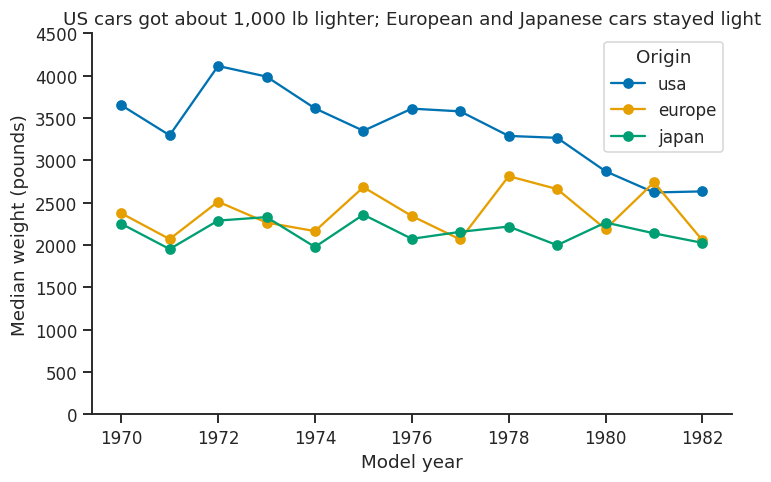

In [41]:
# Team B: your code for round 5
weight_by_year = cars.groupby(["year", "origin"], observed=True)["weight"].median().unstack()
print(weight_by_year)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for origin in ["usa", "europe", "japan"]:
    ax.plot(weight_by_year.index, weight_by_year[origin], marker="o",
            color=ORIGIN_COLOURS[origin], label=origin)
ax.set_ylim(0, 4500)
ax.legend(title="Origin")
ax.set_title("US cars got about 1,000 lb lighter; European and Japanese cars stayed light")
ax.set_xlabel("Model year")
ax.set_ylabel("Median weight (pounds)")
plt.show()

✍️ **Our answer (Team B, round 5)**

**Observation:**

**Evidence:**

**Caveat:**

✍️ **Evaluate the answer**

Now, give a score to the other team's answer using `award()`.

`award(5, 1, "clear observation; evidence with numbers; caveat about ...")`

In [21]:
# Score the OTHER team's answer for round 5 (0, 0.5 or 1), with a one-line reason
# award(5, 1, "clear observation; evidence with numbers; caveat about ...")

---
## Round 6 · Week 8: correlation heatmaps, Robinson form and seriation

**Hint for both cards:** A: `corr = complete[NUMERIC].corr()`, `D = 1 - corr.values`, then `order = seriate(D)` and `ar_events(...)` before and after. B: `complete[NUMERIC].cov()`; a diverging map centred on zero for correlation.

### Card A (Team A answers)

**Question.** Draw the **correlation heatmap** of the 7 numeric variables (use `complete`), first in the file's order, then **seriated**. Which groups of variables appear, and how much does seriation improve the order (gradient-condition violations before and after)?

In [22]:
# Team A: your code for round 6

✍️ **Our answer (Team A, round 6)**

**Observation:**

**Evidence:**

**Caveat:**

### Card B (Team B answers)

**Question.** Draw the **covariance** and the **correlation** heatmaps of the same 7 variables side by side (use `complete`). Why would the covariance heatmap mislead a reader?

standard deviations:
mpg               7.8
cylinders         1.7
displacement    104.6
horsepower       38.5
weight          849.4
acceleration      2.8
year              3.7
dtype: float64


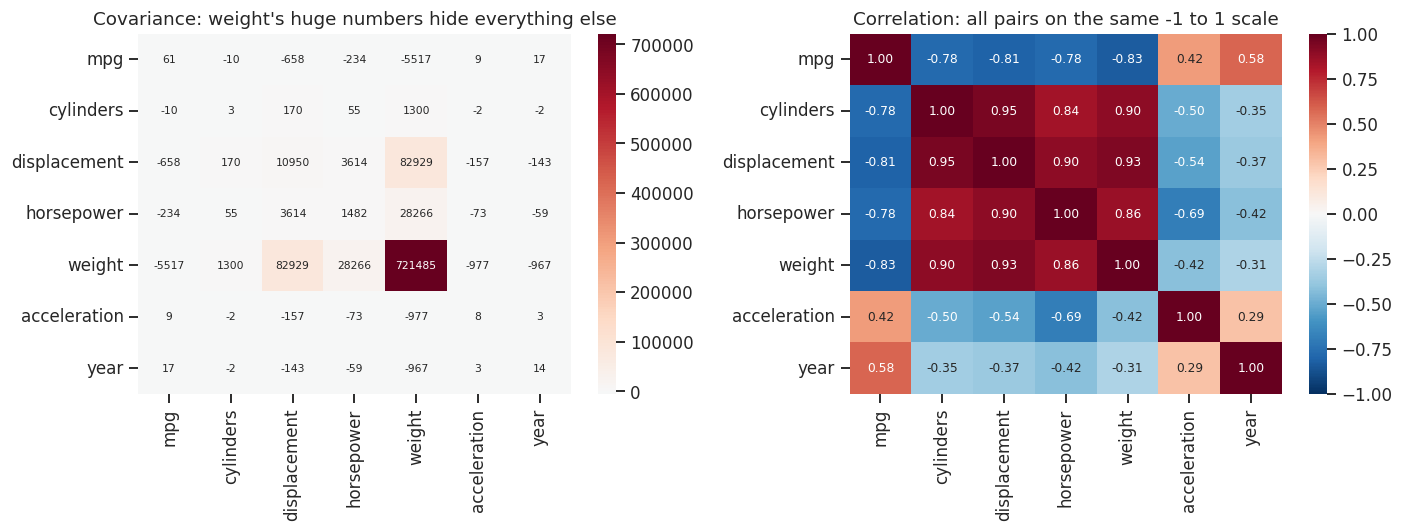

In [42]:
# Team B: your code for round 6
cov = complete[NUMERIC].cov()
corr = complete[NUMERIC].corr()
print("standard deviations:")
print(complete[NUMERIC].std().round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cov, annot=True, fmt=".0f", cmap="RdBu_r", center=0, ax=axes[0], annot_kws={"size": 7})
axes[0].set_title("Covariance: weight's huge numbers hide everything else")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[1], annot_kws={"size": 8})
axes[1].set_title("Correlation: all pairs on the same -1 to 1 scale")
plt.tight_layout()
plt.show()

✍️ **Our answer (Team B, round 6)**

**Observation:**

**Evidence:**

**Caveat:**

✍️ **Evaluate the answer**

Now, give a score to the other team's answer using `award()`.

`award(6, 1, "clear observation; evidence with numbers; caveat about ...")`

In [24]:
# Score the OTHER team's answer for round 6 (0, 0.5 or 1), with a one-line reason
# award(6, 1, "clear observation; evidence with numbers; caveat about ...")

---
## Round 7 · Week 8: clustered heatmaps and k-means

**Hint for both cards:** A: `sns.clustermap(Z, method='ward', row_colors=...)`, then `fcluster(..., 3, 'maxclust')` and `pd.crosstab` with origin. B: `silhouette_score` for k = 2 to 7; `KMeans(n_clusters=k, n_init=10, random_state=445)`; sort the distance matrix by the labels.

### Card A (Team A answers)

**Question.** Draw a **clustered heatmap** of the cars × standardised variables (`Z`), with a strip showing each car's **origin** (added only as a check). Into how many main groups do the cars fall, and do they match origin?

In [25]:
# Team A: your code for round 7

✍️ **Our answer (Team A, round 7)**

**Observation:**

**Evidence:**

**Caveat:**

### Card B (Team B answers)

**Question.** Use **k-means** on `Z`: choose k with the **silhouette**, then **reorder the distance matrix** by cluster. Describe the clusters (for example by cylinders and mpg).

k = 2  silhouette = 0.481
k = 3  silhouette = 0.354
k = 4  silhouette = 0.349
k = 5  silhouette = 0.33
k = 6  silhouette = 0.276
k = 7  silhouette = 0.273
          mpg  cylinders  horsepower  weight    year
cluster                                             
0        26.0        4.0        86.0  2500.0  1977.0
1        14.5        8.0       150.0  4135.0  1973.0
cluster
0    287
1    105
Name: count, dtype: int64


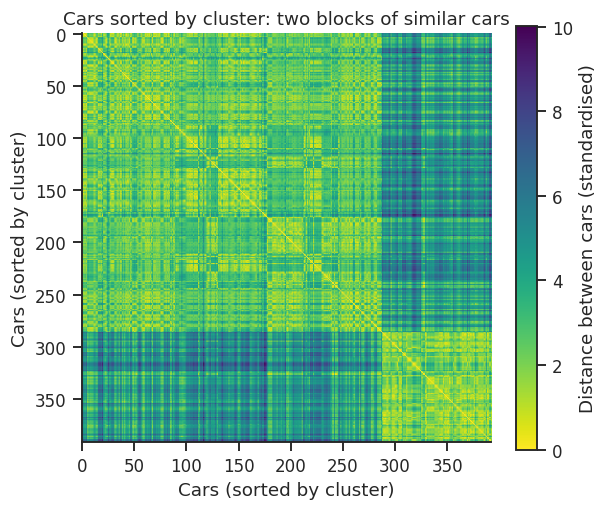

In [43]:
# Team B: your code for round 7
# 1. Choose k with the silhouette score
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=445).fit(Z)
    print("k =", k, " silhouette =", round(silhouette_score(Z, km.labels_), 3))

# 2. Fit k-means with the best k (k = 2 has the highest silhouette)
km = KMeans(n_clusters=2, n_init=10, random_state=445).fit(Z)
clustered = complete.copy()
clustered["cluster"] = km.labels_
print(clustered.groupby("cluster")[["mpg", "cylinders", "horsepower", "weight", "year"]].median())
print(clustered["cluster"].value_counts())

# 3. Distance matrix, with cars sorted by cluster
D = squareform(pdist(Z))
order = np.argsort(km.labels_)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(D[order][:, order], cmap="viridis_r")
fig.colorbar(im, label="Distance between cars (standardised)")
ax.set_title("Cars sorted by cluster: two blocks of similar cars")
ax.set_xlabel("Cars (sorted by cluster)")
ax.set_ylabel("Cars (sorted by cluster)")
plt.show()

✍️ **Our answer (Team B, round 7)**

**Observation:**

**Evidence:**

**Caveat:**

✍️ **Evaluate the answer**

Now, give a score to the other team's answer using `award()`.

`award(7, 1, "clear observation; evidence with numbers; caveat about ...")`

In [27]:
# Score the OTHER team's answer for round 7 (0, 0.5 or 1), with a one-line reason
# award(7, 1, "clear observation; evidence with numbers; caveat about ...")

---
## Round 8 · Week 8: spectral seriation

**Hint for both cards:** Correlate the Fiedler vector with each variable (`np.corrcoef`), then plot that variable in spectral order. B: plot year along the order, coloured by origin.

### Card A (Team A answers)

**Question.** Use **spectral seriation** (`fiedler_order(Z.values)`) to order the cars. Which **variable** does the gradient follow most closely? Show it.

In [28]:
# Team A: your code for round 8

✍️ **Our answer (Team A, round 8)**

**Observation:**

**Evidence:**

**Caveat:**

### Card B (Team B answers)

**Question.** Use **spectral seriation** to order the cars. How do **model year** and **origin** vary along the spectral order? Show it.

correlation of Fiedler vector with year: 0.39
          year    mpg  weight
start   1974.0  15.00  3962.0
middle  1979.0  25.05  2764.5
end     1975.0  28.00  2130.0
origin   usa  europe  japan
row_0                      
start   0.98    0.02   0.00
middle  0.65    0.12   0.22
end     0.24    0.38   0.38


/tmp/ipykernel_1123/12535804.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(ordered.groupby(part)[["year", "mpg", "weight"]].median())


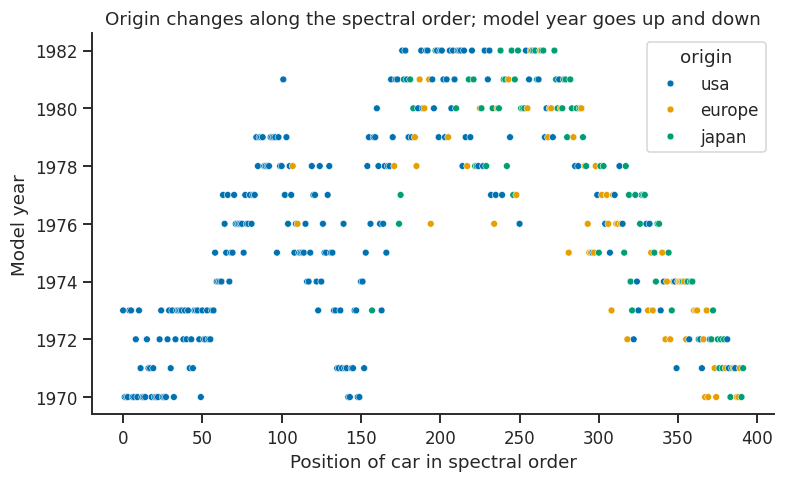

In [44]:
# Team B: your code for round 8
fiedler, order = fiedler_order(Z.values)
ordered = complete.iloc[order].reset_index(drop=True)
print("correlation of Fiedler vector with year:", round(np.corrcoef(fiedler, complete["year"])[0, 1], 2))

# Split the order into three parts and compare them
part = pd.qcut(ordered.index, 3, labels=["start", "middle", "end"])
print(ordered.groupby(part)[["year", "mpg", "weight"]].median())
print(pd.crosstab(part, ordered["origin"], normalize="index").round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.scatterplot(x=ordered.index, y=ordered["year"], hue=ordered["origin"],
                palette=ORIGIN_COLOURS, s=20, ax=ax)
ax.set_title("Origin changes along the spectral order; model year goes up and down")
ax.set_xlabel("Position of car in spectral order")
ax.set_ylabel("Model year")
plt.show()

✍️ **Our answer (Team B, round 8)**

**Observation:**

**Evidence:**

**Caveat:**

✍️ **Evaluate the answer**

Now, give a score to the other team's answer using `award()`.

`award(8, 1, "clear observation; evidence with numbers; caveat about ...")`

In [30]:
# Score the OTHER team's answer for round 8 (0, 0.5 or 1), with a one-line reason
# award(8, 1, "clear observation; evidence with numbers; caveat about ...")

---
## Final question (both teams): the tie-break

**Question.** Write **one** insight statement for a **non-specialist** reader (a car buyer in 1982): *what made a car fuel-efficient in these data?* Combine at least one Week 7 finding and one Week 8 (matrix) finding, with one chart.

The **tutor** scores both answers from 0 to 2: 2 for a clear, accurate statement a non-specialist could act on, with evidence and a caveat; 1 for a correct but technical or incomplete one; 0 otherwise. This score breaks a tie.

weight
(1500, 2250]    31.85
(2250, 3000]    25.00
(3000, 3750]    19.00
(3750, 5200]    14.00
Name: mpg, dtype: float64
          mpg  weight  cylinders
cluster                         
0        26.0  2500.0        4.0
1        14.5  4135.0        8.0


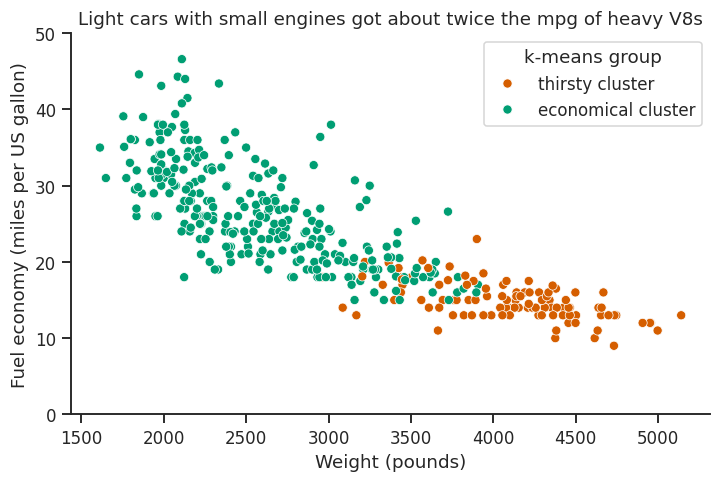

In [45]:
# Your code for the final question
# Week 7 finding: mpg in weight bands
band = pd.cut(complete["weight"], bins=[1500, 2250, 3000, 3750, 5200])
print(complete.groupby(band, observed=True)["mpg"].median())

# Week 8 finding: the two k-means clusters from round 7
km = KMeans(n_clusters=2, n_init=10, random_state=445).fit(Z)
final = complete.copy()
final["cluster"] = km.labels_
print(final.groupby("cluster")[["mpg", "weight", "cylinders"]].median())
# Give the clusters names (check the table above: cluster 0 has the higher mpg)
final["group"] = final["cluster"].map({0: "economical cluster", 1: "thirsty cluster"})

fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.scatterplot(data=final, x="weight", y="mpg", hue="group",
                palette={"economical cluster": OKABE_ITO[2], "thirsty cluster": OKABE_ITO[5]}, ax=ax)
ax.legend(title="k-means group")
ax.set_ylim(0, 50)
ax.set_title("Light cars with small engines got about twice the mpg of heavy V8s")
ax.set_xlabel("Weight (pounds)")
ax.set_ylabel("Fuel economy (miles per US gallon)")
plt.show()

✍️ **Our final answer**

**Observation:**

**Evidence:**

**Caveat:**

---
## Results

Run the cell below to see the scores your team gave the other team, and save them to a file. **Send the file to the tutor** (via email or MS teams): the tutor adds the two teams' files to find the winner.

In [32]:
board = scoreboard()
with open(f"scores_given_by_team_{MY_TEAM}.json", "w") as f:
    json.dump({"team": MY_TEAM, "team_name": TEAM_NAME, "scores_given_to": OTHER_TEAM, "scores": SCORES_GIVEN}, f, indent=2)
print(f"saved scores_given_by_team_{MY_TEAM}.json")
board

Points given to Team B so far: 0
saved scores_given_by_team_A.json


""
round


### References

* Quinlan, J. R. (1993). Combining instance-based and model-based learning. *Proceedings of the Tenth International Conference on Machine Learning*, 236–243. Data: UCI Machine Learning Repository, Auto MPG, [doi:10.24432/C5859H](https://doi.org/10.24432/C5859H).
* The Week 7 lecture (the EDA protocol; observation, evidence, caveat) and the Week 8 lecture (seriation, clustering, spectral methods); the ST445 visualisation checklist (Appendix B).